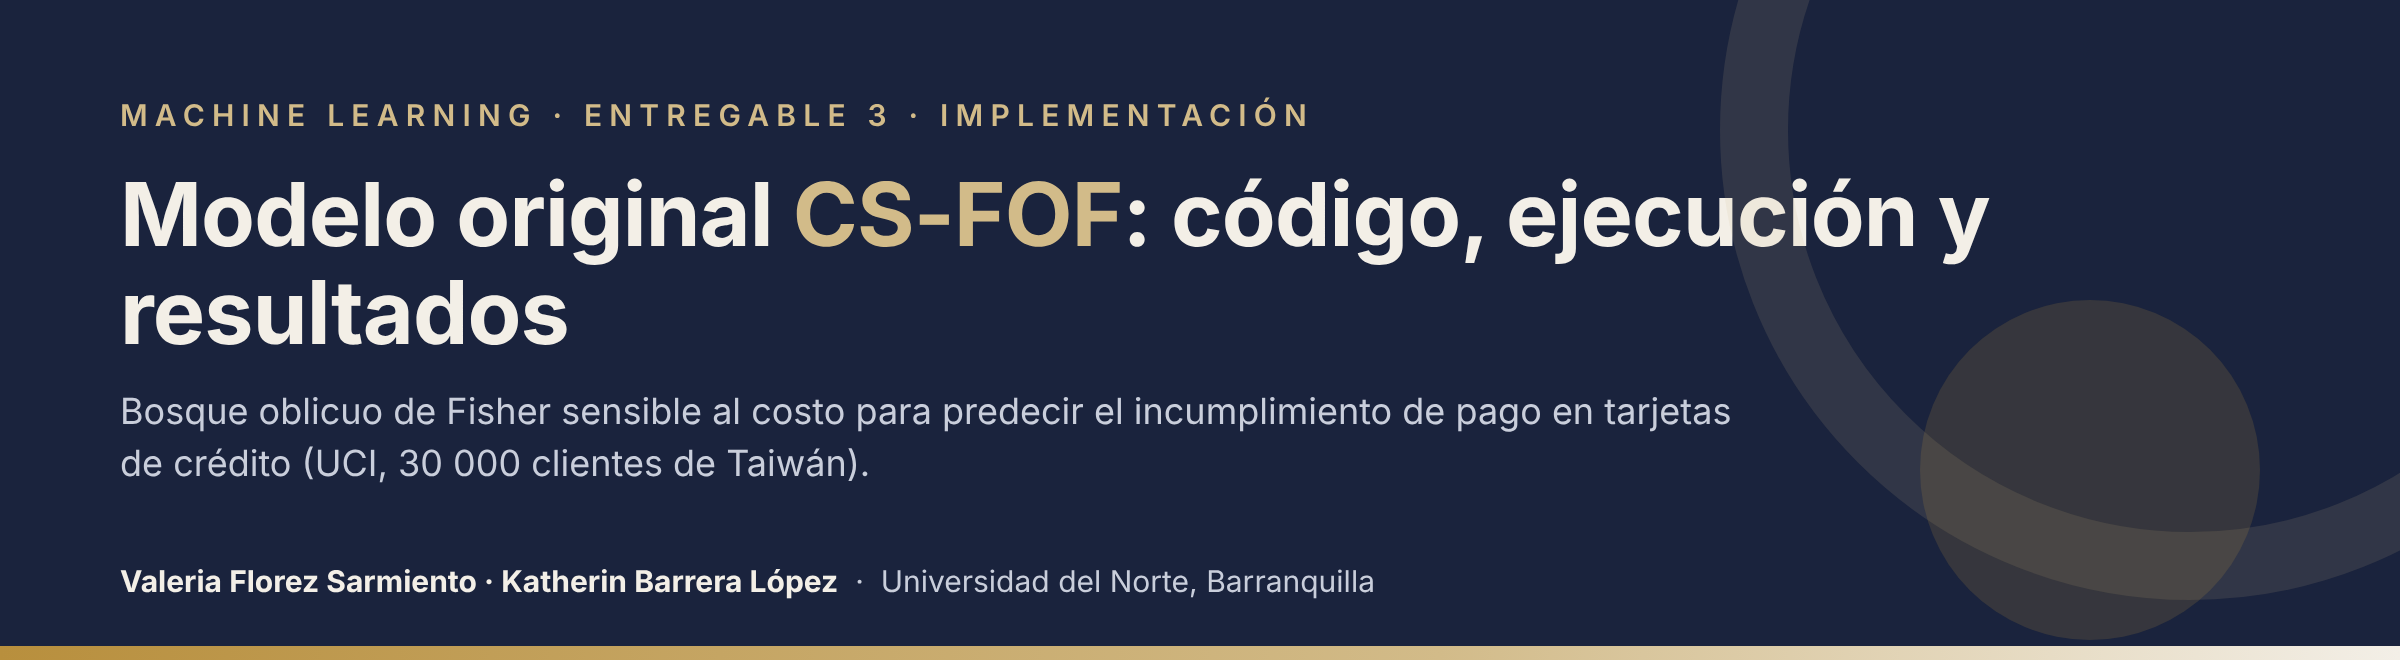

Este notebook reúne, en un solo archivo ejecutado, la implementación del entregable:

1. Preparación de los datos (ETL) y figuras del EDA.
2. Código fuente del modelo original (`src/original_model.py`) y sus pruebas unitarias.
3. Demostración de la idea en datos sintéticos.
4. **Re-ejecución en vivo** del bucle externo de la validación anidada 5 × 5 para CS-FOF, XGBoost y Random Forest, con los hiperparámetros que eligió el bucle interno en cada pliegue.
5. Pruebas estadísticas recalculadas desde los F1 por pliegue (Friedman, Nemenyi, Nadeau-Bengio con Holm).
6. Resultados completos del estudio: calibración, ablación, robustez, SHAP y conjuntos de datos adicionales.

<div style="background:#F3EFE7;border-left:5px solid #1A233D;border-radius:8px;padding:4px 16px;margin:8px 0;color:#1A233D">

**Qué se calcula aquí y qué se lee de disco.** La validación anidada completa (16 combinaciones de balanceo y búsqueda por modelo, con sus bucles internos) tomó varias horas en cuatro equipos (ver capítulo de Reproducibilidad). Aquí se re-ejecuta en vivo lo que cabe en pocos minutos: el ETL, las pruebas, el bucle externo de los tres mejores modelos y las pruebas estadísticas. Las secciones 6 y 7 leen los resultados guardados en `results/` y `experiments/` por los scripts del repositorio, y lo indican en cada caso.

</div>

Ejecución: desde la carpeta `notebooks/`, con el entorno de `requirements.txt` (semilla global 42).

In [1]:
import os, sys, json, time, platform, subprocess, inspect
from pathlib import Path

os.environ.setdefault("CSFOF_N_JOBS", "4")          # procesos para ajustar los árboles de CS-FOF (no cambia el resultado)
PROJECT_ROOT = Path.cwd().parent
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "experiments" / "paper")]

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, xgboost, scipy
from IPython.display import display, Code, Markdown

from src import config
pd.options.display.float_format = "{:,.4f}".format
AZUL, DORADO, GRIS, CREMA, ORO_CLARO = "#1A233D", "#B88F3D", "#8089A0", "#F3EFE7", "#D2BB89"


def tabla(d, fmt="{:,.4f}", resaltar=None):
    # Tabla con la estética del proyecto: encabezado azul marino y la fila de CS-FOF en dorado claro
    num = d.select_dtypes("float").columns
    st = d.style.format(fmt, subset=num).set_table_styles([
        {"selector": "th", "props": f"background-color:{AZUL};color:{CREMA};font-weight:600;padding:6px 10px;"},
        {"selector": "td", "props": "padding:5px 10px;"},
        {"selector": "tbody tr:nth-child(even) td", "props": "background-color:#FBF9F4;"},
    ])
    if resaltar is not None:
        st = st.apply(lambda f: [f"background-color:#F3E6C9;font-weight:600;" if (f.name == resaltar or resaltar in
                                 f.astype(str).values) else "" for _ in f], axis=1)
    return st

print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"scikit-learn {sklearn.__version__} · xgboost {xgboost.__version__} · scipy {scipy.__version__}")
print(f"Sistema: {platform.system()} {platform.release()} · {os.cpu_count()} núcleos")
print(f"Semilla global: {config.RANDOM_STATE} · validación anidada {config.N_OUTER_FOLDS} × {config.N_INNER_FOLDS}")

Python 3.13.17 · numpy 2.5.3 · pandas 3.0.5 · scikit-learn 1.9.1 · xgboost 3.4.1 · scipy 1.18.1
Sistema: Linux 6.18.44-fc-v595 · 4 núcleos
Semilla global: 42 · validación anidada 5 × 5


<h2 style="color:#1A233D;border-bottom:3px solid #D2BB89;padding-bottom:6px;margin-top:22px"><span style="background:#1A233D;color:#D2BB89;border-radius:8px;padding:2px 12px;margin-right:10px">1</span>Datos: ETL</h2>

El conjunto *Default of Credit Card Clients* (UCI, Yeh y Lien, 2009) tiene 30 000 clientes y 23 variables. El ETL de `src/preprocessing.py` aplica los hallazgos del EDA:

1. Reagrupa las categorías no documentadas de `EDUCATION` y `MARRIAGE` en «otros».
2. Elimina las filas duplicadas exactas, antes de cualquier partición.
3. Resume `BILL_AMT1` a `BILL_AMT6`, que son casi colineales (VIF > 20), en nivel medio, tendencia y meses con saldo a favor.
4. Aplica logaritmo con signo a `LIMIT_BAL` y `PAY_AMT1` a `PAY_AMT6`, que son muy asimétricas.

Todos los pasos se hacen fila a fila, salvo la deduplicación, así que no hay fuga de información entre pliegues. La codificación one-hot va dentro del pipeline de cada pliegue.

In [2]:
from src.preprocessing import load_raw_dataset, build_final_dataset, save_final_dataset, remove_duplicate_rows
from src.data_loader import load_processed_dataset, split_features_target

if not config.RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Coloque el .xls de UCI en {config.RAW_DATA_PATH} (ver README).")
crudo = load_raw_dataset()
print("Datos crudos:", crudo.shape)
resumen_etl = save_final_dataset()            # escribe data/processed/ con el dataset final
for k in ("filas_entrada", "filas_duplicadas_eliminadas", "filas_salida", "filas_reasignadas_a_otros",
          "filas_con_factura_negativa"):
    print(f"  {k}: {resumen_etl[k]}")

df, _ = remove_duplicate_rows(load_processed_dataset())
X, y = split_features_target(df)
print(f"\nDataset final: {X.shape[0]:,} clientes × {X.shape[1]} variables · tasa de incumplimiento {y.mean():.1%}")
print(f"Razón de clases n0/n1 = {(y == 0).sum() / (y == 1).sum():.2f} (es el costo c del moroso con class_weight='balanced')")
tabla(X.head(), fmt="{:,.2f}")

Datos crudos: (30000, 24)


  filas_entrada: 30000
  filas_duplicadas_eliminadas: 35
  filas_salida: 29965
  filas_reasignadas_a_otros: {'EDUCATION': 345, 'MARRIAGE': 54}
  filas_con_factura_negativa: 1930

Dataset final: 29,965 clientes × 20 variables · tasa de incumplimiento 22.1%
Razón de clases n0/n1 = 3.52 (es el costo c del moroso con class_weight='balanced')


,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT_MEAN_6M_LOG,BILL_AMT_TREND_6M_LOG,N_CREDIT_BALANCE_MONTHS,LIMIT_BAL_LOG,PAY_AMT1_LOG,PAY_AMT2_LOG,PAY_AMT3_LOG,PAY_AMT4_LOG,PAY_AMT5_LOG,PAY_AMT6_LOG
0,2,2,1,24,2,2,-1,-1,-2,-2,7.16,6.74,0,9.90,0.00,6.54,0.00,0.00,0.00,0.00
1,2,2,2,26,-1,2,0,0,0,2,7.95,-5.52,0,11.70,0.00,6.91,6.91,6.91,0.00,7.60
2,2,2,2,34,0,0,0,0,0,0,9.74,7.53,0,11.41,7.33,7.31,6.91,6.91,6.91,8.52
3,2,2,1,37,0,0,0,0,0,0,10.56,8.46,0,10.82,7.60,7.61,7.09,7.00,6.98,6.91
4,1,2,1,57,-1,0,-1,0,0,0,9.81,-7.71,0,10.82,7.60,10.51,9.21,9.11,6.54,6.52


<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">Figuras del EDA</h3>

Las dos figuras siguientes justifican el ETL y el diseño del modelo. La matriz de Spearman muestra que los atrasos de meses consecutivos están muy correlacionados, de modo que el riesgo vive en combinaciones de variables. El VIF muestra la redundancia de las seis facturas. Las genera `experiments/paper/figuras_paper.py` a partir del `.xls` crudo, con las mismas funciones del paper.

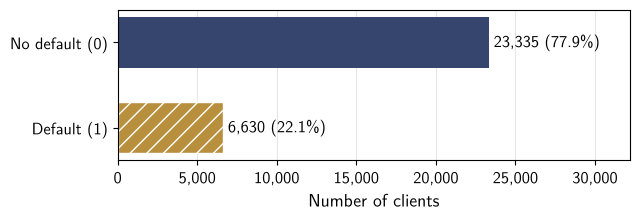

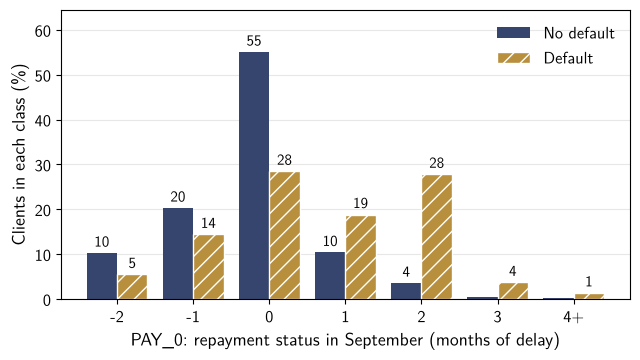

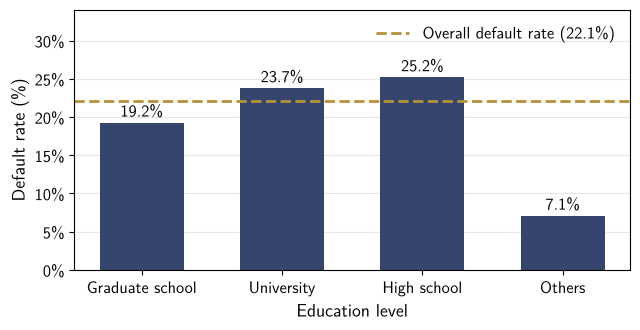

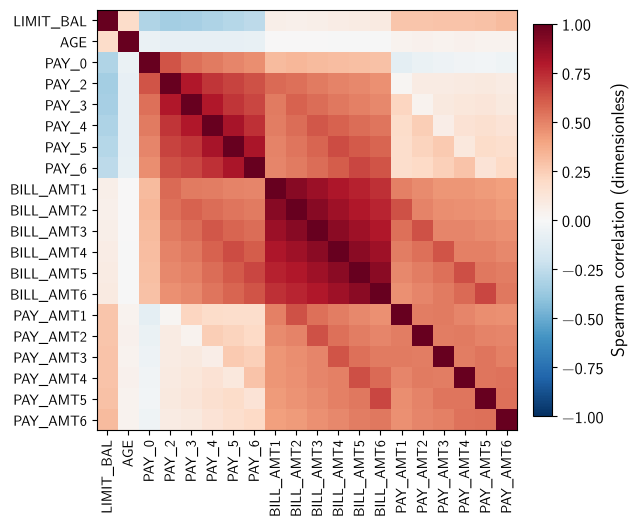

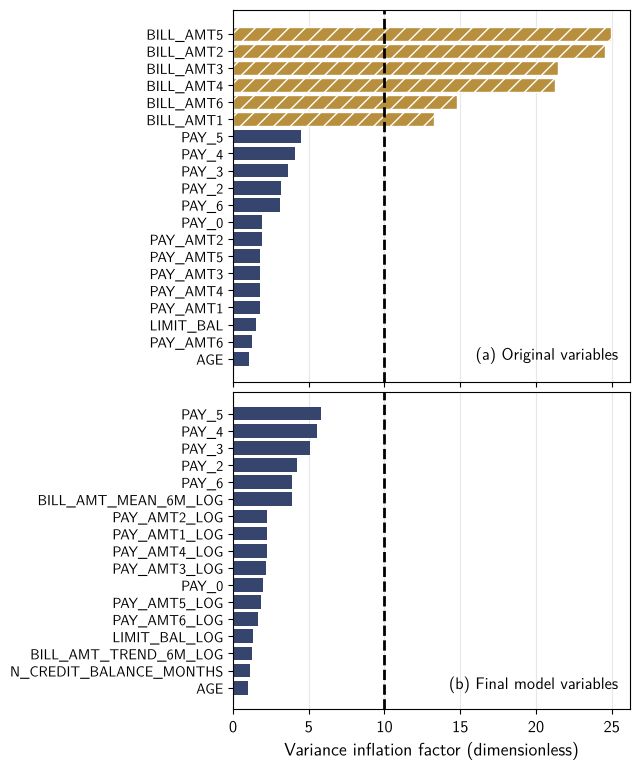

In [3]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import figuras_paper as fp
%matplotlib inline

def mostrar(fig, nombre=None):
    # Muestra en el notebook las figuras del paper en vez de guardarlas en PDF
    fig.tight_layout(pad=0.3)
    display(fig)
    plt.close(fig)

fp.guardar = mostrar
fp.eda()

<h2 style="color:#1A233D;border-bottom:3px solid #D2BB89;padding-bottom:6px;margin-top:22px"><span style="background:#1A233D;color:#D2BB89;border-radius:8px;padding:2px 12px;margin-right:10px">2</span>El modelo original: código fuente</h2>

**Idea.** Un árbol clásico corta sobre una sola variable a la vez (cortes rectos). Como el riesgo depende de combinaciones de variables, la frontera real es oblicua. CS-FOF es un bosque aleatorio programado desde cero en numpy donde **cada nodo pone a competir dos tipos de corte**:

1. **Cortes rectos**, como en Random Forest: umbrales sobre $q$ variables elegidas al azar.
2. **Un corte oblicuo** en la dirección de Fisher, calculada con los clientes del nodo y **ponderada por el costo**:

$$
\mathbf v = (S_w + \varepsilon I)^{-1}(\boldsymbol\mu_1 - \boldsymbol\mu_0),
$$

donde $\boldsymbol\mu_0$ y $\boldsymbol\mu_1$ son las medias ponderadas de cada clase en el nodo, $S_w$ es la dispersión intra-clase ponderada y $\varepsilon$ regulariza cuando $S_w$ es casi singular. Cada moroso pesa $c = n_0/n_1 \approx 3.5$.

Los dos tipos de corte se comparan con el **mismo Gini ponderado por costo**:

$$
G = \frac{W_L}{W}\,\big(1 - p_L^2 - (1-p_L)^2\big) + \frac{W_R}{W}\,\big(1 - p_R^2 - (1-p_R)^2\big),
\qquad p = \frac{\sum_{i} w_i y_i}{\sum_i w_i}.
$$

El nodo se queda con el corte de menor $G$. Por eso el corte elegido nunca es peor que el mejor corte recto (Proposición 1). La predicción del bosque es el promedio de las probabilidades de hoja de los $T$ árboles.

A continuación, el archivo completo de la implementación:

In [4]:
fuente = PROJECT_ROOT / "src" / "original_model.py"
print(f"{fuente.relative_to(PROJECT_ROOT)}: {len(fuente.read_text(encoding='utf-8').splitlines())} líneas")
Code(filename=str(fuente), language="python")

src/original_model.py: 379 líneas


"""CS-FOF: Cost-Sensitive Fisher Oblique Forest (modelo original del proyecto).

Bosque aleatorio cuyos nodos pueden cortar por una combinación lineal de
variables. En cada nodo compiten:

- los cortes por ejes sobre ``q`` variables sorteadas (como en Random Forest), y
- un corte oblicuo por la dirección discriminante de Fisher, ponderada por el
  costo del incumplimiento y calculada SOLO con los clientes de ese nodo.

El nodo se queda con el corte de menor impureza de Gini ponderada.

Implementación propia: solo usa ``numpy`` como herramienta de cálculo (la
clase base de ``scikit-learn`` solo aporta la interfaz ``fit/predict``).

Decisiones de implementación (no cambian el modelo, solo su costo):

1. El árbol crece **por niveles**: todos los nodos de una profundidad se
   procesan a la vez con operaciones vectorizadas, en vez de un nodo por
   llamada recursiva.
2. Los umbrales se buscan con **histogramas** de ``n_bins`` cuantiles, como en
   LightGBM o el modo ``hist`` de XGBoost: los cortes por ejes usan los
   cuantiles de cada variable (calculados una vez por ajuste) y el corte
   oblicuo usa los cuantiles de la proyección dentro de cada nodo.
3. El *bootstrap* se representa con pesos (cuántas veces sale cada cliente)
   en vez de duplicar filas.
"""
from __future__ import annotations

import numpy as np
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y


# ---------------------------------------------------------------------------
# Utilidades
# ---------------------------------------------------------------------------
def _n_features_por_nodo(max_features, p: int) -> int:
    """Número q de variables sorteadas en cada nodo."""
    if max_features is None:
        return p
    if max_features == "sqrt":
        return max(1, int(np.sqrt(p)))
    if max_features == "log2":
        return max(1, int(np.log2(p)))
    if isinstance(max_features, (float, np.floating)) and 0 < max_features <= 1:
        return max(1, int(round(max_features * p)))
    if isinstance(max_features, (int, np.integer)) and max_features >= 1:
        return min(int(max_features), p)
    raise ValueError(f"max_features no válido: {max_features!r}")


def _pesos_de_clase(y: np.ndarray, class_weight) -> np.ndarray:
    """Peso w_i de cada cliente (ecuación de pesos de la metodología).

    ``class_weight=None``: todos pesan 1 (c = 1).
    ``class_weight="balanced"``: el moroso pesa c = n0 / n1.
    ``class_weight={0: a, 1: b}``: pesos explícitos.
    """
    if class_weight is None:
        return np.ones(len(y))
    if class_weight == "balanced":
        n1 = max(int(y.sum()), 1)
        n0 = len(y) - n1
        return np.where(y == 1, n0 / n1, 1.0)
    if isinstance(class_weight, dict):
        return np.where(y == 1, float(class_weight.get(1, 1.0)), float(class_weight.get(0, 1.0)))
    raise ValueError(f"class_weight no válido: {class_weight!r}")


def _gini_ponderado(WL, W1L, WR, W1R):
    """G(L, R) = W_L 2 p_L (1 - p_L) + W_R 2 p_R (1 - p_R), sin dividir por cero."""
    with np.errstate(divide="ignore", invalid="ignore"):
        pL = np.where(WL > 0, W1L / WL, 0.0)
        pR = np.where(WR > 0, W1R / WR, 0.0)
    return WL * 2 * pL * (1 - pL) + WR * 2 * pR * (1 - pR)


def _mejor_umbral_por_histograma(nodo, bins, w, wy, cnt, n_nodos, n_bins, min_leaf):
    """Mejor corte «bin <= b» de cada nodo a partir de histogramas ponderados.

    Devuelve, por nodo, (impureza mínima, bin óptimo). Impureza = +inf si
    ningún corte deja al menos ``min_leaf`` observaciones a cada lado.
    """
    clave = nodo * n_bins + bins
    tam = n_nodos * n_bins
    H_w = np.bincount(clave, weights=w, minlength=tam).reshape(n_nodos, n_bins)
    H_wy = np.bincount(clave, weights=wy, minlength=tam).reshape(n_nodos, n_bins)
    H_c = np.bincount(clave, weights=cnt, minlength=tam).reshape(n_nodos, n_bins)
    WL = np.cumsum(H_w, axis=1)[:, :-1]
    W1L 

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">Pruebas unitarias</h3>

`tests/test_original_model.py` verifica las propiedades del algoritmo:

- que un solo corte oblicuo capte una frontera diagonal;
- la Proposición 1;
- la compatibilidad con scikit-learn;
- la reproducibilidad con la semilla;
- que el resultado no dependa de `n_jobs`.

Las mismas pruebas corren en GitHub Actions en cada *push* (`.github/workflows/tests.yml`).

In [5]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests/", "-v", "--color=no", "-p", "no:cacheprovider", "-W", "ignore"],
                   cwd=PROJECT_ROOT, capture_output=True, text=True)
print("\n".join(l for l in r.stdout.splitlines() if "PASSED" in l or "FAILED" in l or "passed" in l or "failed" in l))

tests/test_artifacts.py::test_indice_tiene_los_10_modelos PASSED         [  2%]
tests/test_artifacts.py::test_ida_y_vuelta[cs_fof] PASSED                [  5%]
tests/test_artifacts.py::test_ida_y_vuelta[catboost] PASSED              [  7%]
tests/test_artifacts.py::test_ida_y_vuelta[xgboost] PASSED               [ 10%]
tests/test_artifacts.py::test_ida_y_vuelta[lightgbm] PASSED              [ 12%]
tests/test_artifacts.py::test_ida_y_vuelta[random_forest] PASSED         [ 15%]
tests/test_artifacts.py::test_ida_y_vuelta[svm] PASSED                   [ 17%]
tests/test_artifacts.py::test_ida_y_vuelta[knn] PASSED                   [ 20%]
tests/test_artifacts.py::test_ida_y_vuelta[decision_tree] PASSED         [ 23%]
tests/test_artifacts.py::test_ida_y_vuelta[logistic_regression] PASSED   [ 25%]
tests/test_artifacts.py::test_ida_y_vuelta[naive_bayes] PASSED           [ 28%]
tests/test_artifacts.py::test_metadata_completa[cs_fof] PASSED           [ 30%]
tests/test_artifacts.py::test_metadata_c

<h2 style="color:#1A233D;border-bottom:3px solid #D2BB89;padding-bottom:6px;margin-top:22px"><span style="background:#1A233D;color:#D2BB89;border-radius:8px;padding:2px 12px;margin-right:10px">3</span>Demostración en datos sintéticos</h2>

Dos clases con frontera diagonal (390 negativos y 110 positivos, aproximadamente la proporción del problema real). La figura compara un árbol clásico de profundidad 4 (una escalera de cortes rectos) con un solo corte en la dirección de Fisher ponderada por costo, e indica la reducción de impureza (Gini ponderado) de cada opción con el mismo número de cortes. La ventaja del corte oblicuo es grande con pocos cortes y se reduce a medida que la escalera se acerca a la diagonal. Por eso, en un bosque con miles de cortes, la ganancia final es pequeña.

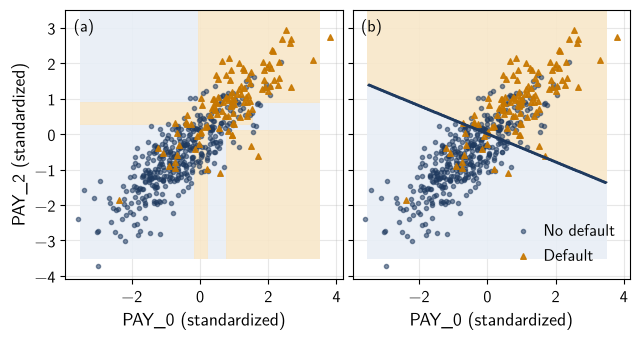

In [6]:
fp.corte_oblicuo()

<h2 style="color:#1A233D;border-bottom:3px solid #D2BB89;padding-bottom:6px;margin-top:22px"><span style="background:#1A233D;color:#D2BB89;border-radius:8px;padding:2px 12px;margin-right:10px">4</span>Re-ejecución del bucle externo de la validación anidada</h2>

Protocolo (`experiments/protocolo.md`):

- Validación anidada estratificada con 5 pliegues externos y 5 internos, semilla 42. Es la misma partición para todos los modelos.
- Cada pliegue externo deja fuera el 20 % de los clientes. El bucle interno busca los hiperparámetros solo con el 80 % restante y el modelo se evalúa una sola vez en el pliegue externo.
- Métrica principal: F1 de la clase *default*.

Aquí se re-entrena **en vivo** el bucle externo de los tres mejores modelos, con su mejor combinación de balanceo y búsqueda, usando los hiperparámetros que el bucle interno eligió en cada pliegue (guardados en `results/`):

| Modelo | Balanceo | Búsqueda |
|---|---|---|
| CS-FOF | pesos de clase | aleatoria (25 configuraciones) |
| XGBoost | pesos de clase (`scale_pos_weight`) | bayesiana (Optuna, 30 ensayos) |
| Random Forest | pesos de clase | aleatoria (25 configuraciones) |

El bucle interno completo (25 a 30 configuraciones × 5 pliegues internos × 5 externos) no se repite aquí porque toma horas.

El esquema de la validación anidada es el de la Figura 6 del paper:

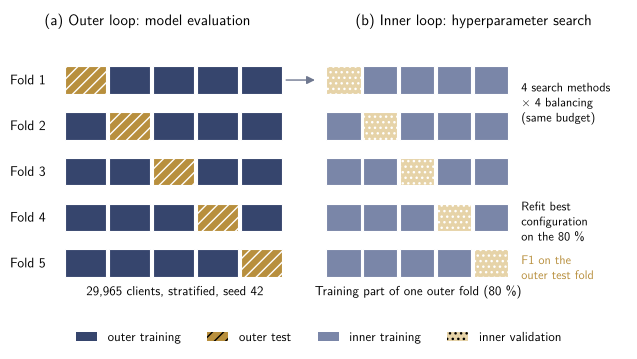

In [7]:
fig = fp.validacion_anidada()
display(fig); plt.close(fig)

In [8]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from src.balancing import build_pipeline
from src.models import MODEL_REGISTRY
from src.preprocessing import get_preprocessing_steps

guardado = pd.concat([pd.read_csv(PROJECT_ROOT / "results" / "experiments_5x5__cs_fof.csv"),
                      pd.read_csv(PROJECT_ROOT / "results" / "experiments_5x5__local.csv")])
ELEGIDOS = {"cs_fof": "random_search", "xgboost": "bayesian_optuna", "random_forest": "random_search"}
NOMBRE = {"cs_fof": "CS-FOF", "xgboost": "XGBoost", "random_forest": "Random Forest"}

externo = StratifiedKFold(n_splits=config.N_OUTER_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
pliegues = list(externo.split(X, y))
filas, oof, modelos_cs = [], {m: np.zeros(len(y)) for m in ELEGIDOS}, []
for m, metodo in ELEGIDOS.items():
    g = guardado[(guardado.model == m) & (guardado.technique == "class_weight") & (guardado.method == metodo)].iloc[0]
    params, f1_guardado = json.loads(g.best_params_per_fold), json.loads(g.f1_per_fold)
    spec = MODEL_REGISTRY[m]
    for i, (tr, te) in enumerate(pliegues):
        t0 = time.time()
        pipe = build_pipeline(spec, "class_weight", y_train=y.iloc[tr],
                              preprocessing_steps=get_preprocessing_steps(spec), **params[i])
        pipe.fit(X.iloc[tr], y.iloc[tr])
        p = pipe.predict_proba(X.iloc[te])[:, 1]; oof[m][te] = p
        pred = (p >= 0.5).astype(int)
        if m == "cs_fof":
            modelos_cs.append(pipe[-1])
        filas.append({"modelo": NOMBRE[m], "pliegue": i + 1, "F1 recalculado": f1_score(y.iloc[te], pred),
                      "F1 guardado": f1_guardado[i], "precisión": precision_score(y.iloc[te], pred),
                      "recall": recall_score(y.iloc[te], pred), "ROC-AUC": roc_auc_score(y.iloc[te], p),
                      "segundos": time.time() - t0})
    print(f"{NOMBRE[m]:14s} listo · hiperparámetros del pliegue 1: {params[0]}")

R = pd.DataFrame(filas)
R["diferencia"] = R["F1 recalculado"] - R["F1 guardado"]
tabla(R, resaltar="CS-FOF")

CS-FOF         listo · hiperparámetros del pliegue 1: {'eps': 0.2646573170201432, 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 14, 'n_estimators': 330}


XGBoost        listo · hiperparámetros del pliegue 1: {'n_estimators': 192, 'max_depth': 8, 'learning_rate': 0.015395035354094939, 'subsample': 0.5980334279885874, 'colsample_bytree': 0.8368422532774571, 'reg_lambda': 0.6318333899511757}


Random Forest  listo · hiperparámetros del pliegue 1: {'max_depth': 11, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 45, 'n_estimators': 235}


,modelo,pliegue,F1 recalculado,F1 guardado,precisión,recall,ROC-AUC,segundos,diferencia
0,CS-FOF,1,0.5497,0.5484,0.5213,0.5814,0.7870,8.8331,0.0013
1,CS-FOF,2,0.5434,0.5447,0.5330,0.5543,0.7754,18.1101,-0.0013
2,CS-FOF,3,0.5416,0.5441,0.5062,0.5822,0.7801,13.1781,-0.0025
3,CS-FOF,4,0.5574,0.5572,0.5130,0.6101,0.7982,9.1449,0.0002
4,CS-FOF,5,0.5450,0.5453,0.4969,0.6033,0.7821,8.1525,-0.0004
5,XGBoost,1,0.5431,0.5478,0.5006,0.5935,0.7873,1.1321,-0.0047
6,XGBoost,2,0.5406,0.5428,0.5039,0.5830,0.7733,3.6810,-0.0023
7,XGBoost,3,0.5405,0.5403,0.4714,0.6335,0.7801,0.5731,0.0002
8,XGBoost,4,0.5592,0.5619,0.4877,0.6554,0.7970,0.6582,-0.0027
9,XGBoost,5,0.5392,0.5399,0.4864,0.6048,0.7803,1.7881,-0.0007


In [9]:
res = (R.groupby("modelo", sort=False)
         .agg(F1_recalculado=("F1 recalculado", "mean"), desv=("F1 recalculado", lambda s: s.std(ddof=1)),
              F1_guardado=("F1 guardado", "mean"), precision=("precisión", "mean"), recall=("recall", "mean"),
              roc_auc=("ROC-AUC", "mean"), max_dif_abs=("diferencia", lambda s: s.abs().max()),
              segundos_por_pliegue=("segundos", "mean")))
tabla(res, resaltar="CS-FOF")

,F1_recalculado,desv,F1_guardado,precision,recall,roc_auc,max_dif_abs,segundos_por_pliegue
modelo,,,,,,,,
CS-FOF,0.5474,0.0063,0.5479,0.5141,0.5863,0.7846,0.0025,11.4838
XGBoost,0.5445,0.0083,0.5466,0.4900,0.6140,0.7836,0.0047,1.5665
Random Forest,0.5452,0.0077,0.5452,0.4974,0.6041,0.7831,0.0000,8.8499


<div style="background:#F3EFE7;border-left:5px solid #B88F3D;border-radius:8px;padding:4px 16px;margin:8px 0;color:#1A233D">

**Lectura.** Random Forest reproduce exactamente los F1 guardados. En CS-FOF y XGBoost la diferencia por pliegue es de milésimas: las corridas originales se hicieron en Windows y este notebook corre en Linux, y pequeñas diferencias numéricas (cuantiles de los histogramas, sumas en punto flotante) cambian algunos cortes. Las medias quedan dentro de la desviación entre pliegues. Las conclusiones no cambian: los tres modelos quedan prácticamente empatados.

</div>

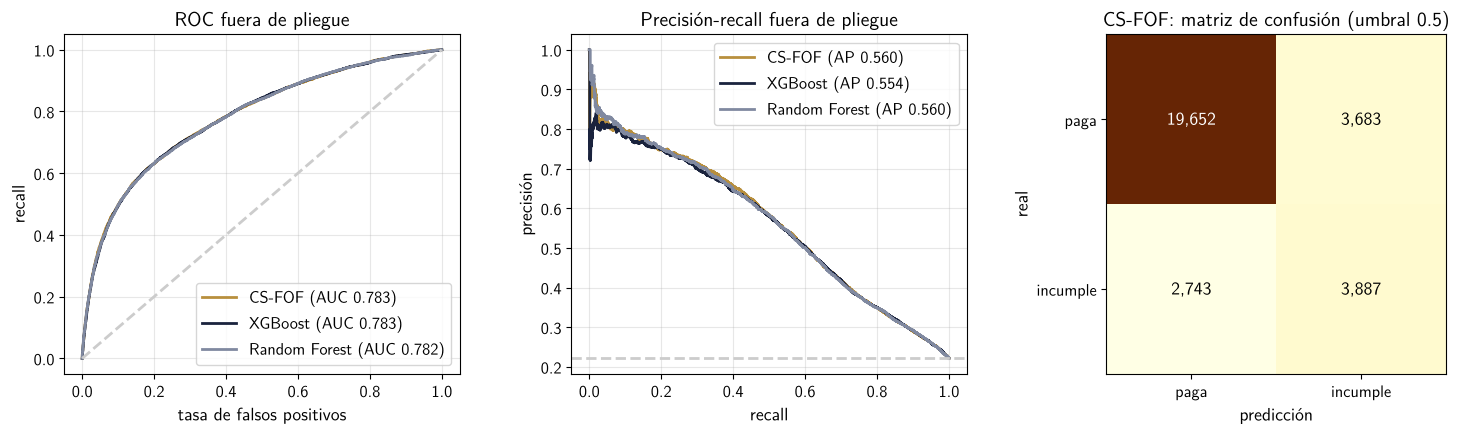

CS-FOF detecta 3,887 de 6,630 incumplimientos (59%) con 3,683 falsas alarmas.
Fracción de cortes oblicuos por pliegue: ['72%', '72%', '74%', '72%', '72%']


In [10]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
colores = {"cs_fof": DORADO, "xgboost": AZUL, "random_forest": GRIS}
for m in ELEGIDOS:
    fpr, tpr, _ = roc_curve(y, oof[m]); pr, rc, _ = precision_recall_curve(y, oof[m])
    axs[0].plot(fpr, tpr, color=colores[m], lw=2, label=f"{NOMBRE[m]} (AUC {roc_auc_score(y, oof[m]):.3f})")
    axs[1].plot(rc, pr, color=colores[m], lw=2, label=f"{NOMBRE[m]} (AP {average_precision_score(y, oof[m]):.3f})")
axs[0].plot([0, 1], [0, 1], ls="--", c="#ccc"); axs[0].set(xlabel="tasa de falsos positivos", ylabel="recall",
                                                      title="ROC fuera de pliegue")
axs[1].axhline(y.mean(), ls="--", c="#ccc"); axs[1].set(xlabel="recall", ylabel="precisión",
                                                      title="Precisión-recall fuera de pliegue")
for a in axs[:2]: a.legend(loc="lower right" if a is axs[0] else "upper right")
cm = confusion_matrix(y, (oof["cs_fof"] >= 0.5).astype(int))
axs[2].imshow(cm, cmap="YlOrBr"); axs[2].grid(False)
for (i, j), v in np.ndenumerate(cm):
    axs[2].text(j, i, f"{v:,}", ha="center", va="center", fontsize=13,
                color="white" if v > cm.max() / 2 else "black")
axs[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["paga", "incumple"], yticklabels=["paga", "incumple"],
           xlabel="predicción", ylabel="real", title="CS-FOF: matriz de confusión (umbral 0.5)")
plt.tight_layout(); plt.show()
tn, fp_, fn, tp = cm.ravel()
print(f"CS-FOF detecta {tp:,} de {tp + fn:,} incumplimientos ({tp / (tp + fn):.0%}) con {fp_:,} falsas alarmas.")
print("Fracción de cortes oblicuos por pliegue:", [f"{m.fraccion_cortes_oblicuos():.0%}" for m in modelos_cs])

<h2 style="color:#1A233D;border-bottom:3px solid #D2BB89;padding-bottom:6px;margin-top:22px"><span style="background:#1A233D;color:#D2BB89;border-radius:8px;padding:2px 12px;margin-right:10px">5</span>Pruebas estadísticas, recalculadas desde los F1 por pliegue</h2>

Se toma la mejor combinación de cada uno de los 8 modelos (CS-FOF y los 7 de referencia) y sus F1 en los 5 pliegues externos guardados.

- **Friedman** contrasta si los 8 modelos son equivalentes en rango medio.
- **Nemenyi** da la diferencia crítica: $\mathrm{CD} = q_\alpha\sqrt{k(k+1)/(6N)}$, con $k = 8$ y $N = 5$.
- **Nadeau-Bengio** es un $t$ corregido porque los pliegues comparten datos de entrenamiento: $t = \bar d \,/\, \sqrt{(1/k + n_2/n_1)\, s_d^2}$. Se aplica a cada contraste de CS-FOF frente a un rival, con corrección de **Holm** por comparaciones múltiples.

In [11]:
from scipy import stats
maestra = pd.read_csv(PROJECT_ROOT / "results" / "master_table_e3.csv")      # tabla maestra: todas las combinaciones 5 × 5
mejor = maestra.loc[maestra.groupby("model")["f1_mean"].idxmax()].set_index("model")
mejor = mejor.loc[[m for m in ["cs_fof", "xgboost", "random_forest", "svm", "knn", "decision_tree",
                               "logistic_regression", "naive_bayes"] if m in mejor.index]]
F = pd.DataFrame({m: json.loads(r.f1_per_fold) for m, r in mejor.iterrows()})
display(tabla(mejor[["technique", "method", "f1_mean", "f1_std", "roc_auc_mean"]], resaltar="cs_fof"))

chi2, p = stats.friedmanchisquare(*[F[c] for c in F])
rangos = F.rank(axis=1, ascending=False).mean().sort_values()
k, N = F.shape[1], F.shape[0]
q = {8: 3.031}[k]                                          # q_0.05 de Nemenyi para k = 8 (Demšar, 2006)
cd = q * np.sqrt(k * (k + 1) / (6 * N))
print(f"Friedman: chi2 = {chi2:.2f}, p = {p:.2e} · diferencia crítica de Nemenyi = {cd:.2f}")
print("Rangos medios:", ", ".join(f"{m} {r:.1f}" for m, r in rangos.items()))

n = len(y); n2 = n // 5; n1 = n - n2
filas = []
for rival in F.columns.drop("cs_fof"):
    d = F["cs_fof"] - F[rival]
    t = d.mean() / np.sqrt((1 / N + n2 / n1) * d.var(ddof=1))
    filas.append({"rival": rival, "dif. F1": d.mean(), "t Nadeau-Bengio": t,
                  "p": 2 * stats.t.sf(abs(t), N - 1), "CS-FOF gana en": f"{(d > 0).sum()} de {N}"})
NB = pd.DataFrame(filas)
orden = np.argsort(NB["p"].to_numpy()); m_ = len(NB)
aj = np.maximum.accumulate(NB["p"].to_numpy()[orden] * (m_ - np.arange(m_))).clip(max=1)
NB.loc[orden, "p Holm"] = aj
tabla(NB)

,technique,method,f1_mean,f1_std,roc_auc_mean
model,,,,,
cs_fof,class_weight,random_search,0.5479,0.0054,0.7847
xgboost,class_weight,bayesian_optuna,0.5466,0.0091,0.7828
random_forest,class_weight,random_search,0.5452,0.0077,0.7831
svm,smote,random_search,0.5387,0.0048,0.7638
knn,class_weight,random_search,0.5264,0.0122,0.7629
decision_tree,class_weight,bayesian_optuna,0.5254,0.0043,0.7569
logistic_regression,class_weight,genetic_deap,0.5182,0.0104,0.7449
naive_bayes,smote,grid_search,0.4987,0.0078,0.7454


Friedman: chi2 = 32.93, p = 2.72e-05 · diferencia crítica de Nemenyi = 4.70
Rangos medios: cs_fof 1.4, xgboost 2.2, random_forest 2.4, svm 4.0, knn 5.6, decision_tree 5.6, logistic_regression 6.8, naive_bayes 8.0


,rival,dif. F1,t Nadeau-Bengio,p,CS-FOF gana en,p Holm
0,xgboost,0.0014,0.5261,0.6266,4 de 5,0.6266
1,random_forest,0.0027,1.1634,0.3093,4 de 5,0.6187
2,svm,0.0092,6.9064,0.0023,5 de 5,0.0101
3,knn,0.0216,4.4476,0.0113,5 de 5,0.0338
4,decision_tree,0.0225,10.7904,0.0004,5 de 5,0.0025
5,logistic_regression,0.0297,7.1557,0.0020,5 de 5,0.0101
6,naive_bayes,0.0493,21.1102,0.0000,5 de 5,0.0002


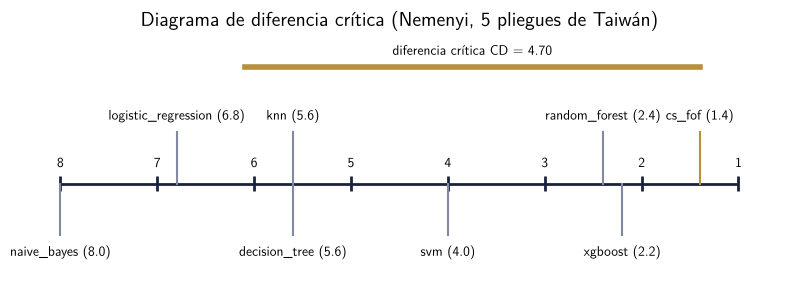

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.set_xlim(0.5, k + 0.5); ax.set_ylim(-1.2, 1.6); ax.invert_xaxis(); ax.axis("off")
ax.hlines(0, 1, k, color=AZUL); ax.vlines(range(1, k + 1), -0.08, 0.08, color=AZUL)
for i in range(1, k + 1): ax.text(i, 0.18, str(i), ha="center", fontsize=10)
for j, (m, r) in enumerate(rangos.items()):
    lado = 1 if j % 2 == 0 else -1
    ax.plot([r, r], [0, 0.55 * lado], color=DORADO if m == "cs_fof" else GRIS, lw=1.5)
    ax.text(r, 0.65 * lado, f"{m} ({r:.1f})", ha="center", va="bottom" if lado > 0 else "top",
            fontsize=10, fontweight="bold" if m == "cs_fof" else "normal")
ax.plot([rangos.iloc[0], rangos.iloc[0] + cd], [1.25, 1.25], color=DORADO, lw=4)
ax.text(rangos.iloc[0] + cd / 2, 1.38, f"diferencia crítica CD = {cd:.2f}", ha="center", fontsize=10)
ax.set_title("Diagrama de diferencia crítica (Nemenyi, 5 pliegues de Taiwán)")
plt.show()

<div style="background:#F3EFE7;border-left:5px solid #B88F3D;border-radius:8px;padding:4px 16px;margin:8px 0;color:#1A233D">

**Lectura.** Friedman rechaza que los 8 modelos sean equivalentes. CS-FOF tiene el mejor rango medio, pero con solo 5 pliegues la diferencia crítica es grande: Nemenyi no separa a CS-FOF de XGBoost ni de Random Forest. Nadeau-Bengio con Holm tampoco encuentra diferencias significativas frente a esos dos ($p > 0.6$), mientras que CS-FOF sí supera a los modelos más simples. Para verificar, se comparan los valores recalculados con los del archivo guardado por `experiments/paper/resultados_paper.py`. Los $p$ sin ajustar coinciden. Los $p$ de Holm del paper son algo mayores en algunos rivales porque allí la corrección se aplica a 10 contrastes: los 7 rivales más tres variantes de regresión logística.

</div>

In [13]:
fr = json.load(open(PROJECT_ROOT / "experiments" / "paper" / "friedman_exigidos.json"))["taiwan"]
print(f"Guardado:     chi2 = {fr['chi2']:.2f}, p = {fr['p_chi2']:.2e}, CD = {fr['nemenyi_cd']:.2f}")
print(f"Recalculado:  chi2 = {chi2:.2f}, p = {p:.2e}, CD = {cd:.2f}")
pg = pd.read_csv(PROJECT_ROOT / "experiments" / "paper" / "pruebas_cs_fof.csv").set_index("baseline")
comp = NB.set_index("rival")[["dif. F1", "p"]].join(pg[["dif_f1", "p_nb"]].rename(
    columns={"dif_f1": "dif. F1 guardada", "p_nb": "p guardado"}))
tabla(comp)

Guardado:     chi2 = 32.93, p = 2.72e-05, CD = 4.70
Recalculado:  chi2 = 32.93, p = 2.72e-05, CD = 4.70


,dif. F1,p,dif. F1 guardada,p guardado
rival,,,,
xgboost,0.0014,0.6266,0.0014,0.6266
random_forest,0.0027,0.3093,0.0027,0.3093
svm,0.0092,0.0023,0.0092,0.0023
knn,0.0216,0.0113,0.0216,0.0113
decision_tree,0.0225,0.0004,0.0225,0.0004
logistic_regression,0.0297,0.0020,0.0297,0.0020
naive_bayes,0.0493,0.0000,0.0493,0.0000


<h2 style="color:#1A233D;border-bottom:3px solid #D2BB89;padding-bottom:6px;margin-top:22px"><span style="background:#1A233D;color:#D2BB89;border-radius:8px;padding:2px 12px;margin-right:10px">6</span>Resultados completos del estudio (leídos de los archivos guardados)</h2>

Las figuras de esta sección son las del paper. `experiments/paper/figuras_paper.py` las genera a partir de los CSV que escribieron los scripts de `experiments/` y `src/`.

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">6.1 F1 por pliegue de los 8 modelos</h3>

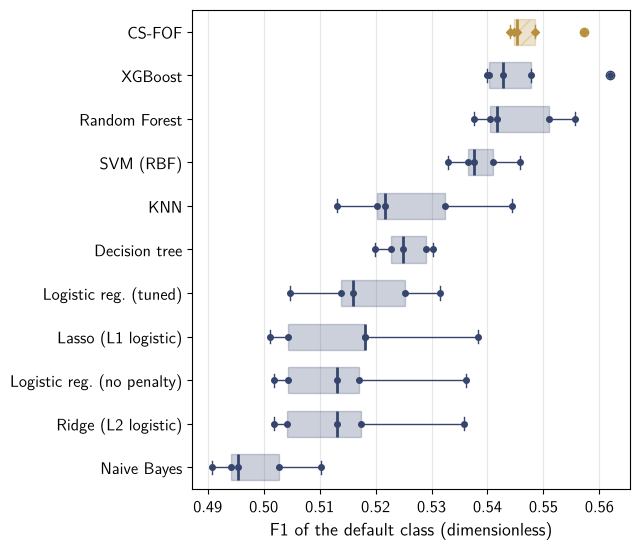

In [14]:
fp.f1_por_pliegue()

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">6.2 Diferencias de F1 frente a cada rival, con intervalos de confianza al 95 %</h3>

Si el intervalo cruza el cero, no hay evidencia de diferencia.

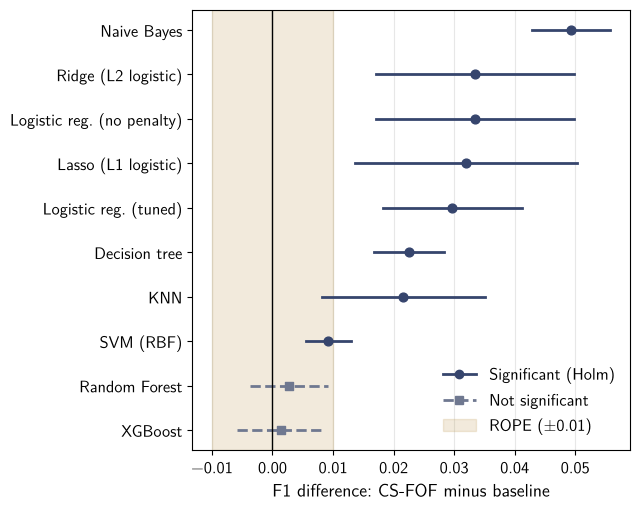

In [15]:
fp.intervalos()

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">6.3 ROC, precisión-recall, calibración y matriz de confusión fuera de pliegue (CS-FOF frente a XGBoost)</h3>

   cs_fof: AUC 0.783  AP 0.560
   xgboost: AUC 0.783  AP 0.555


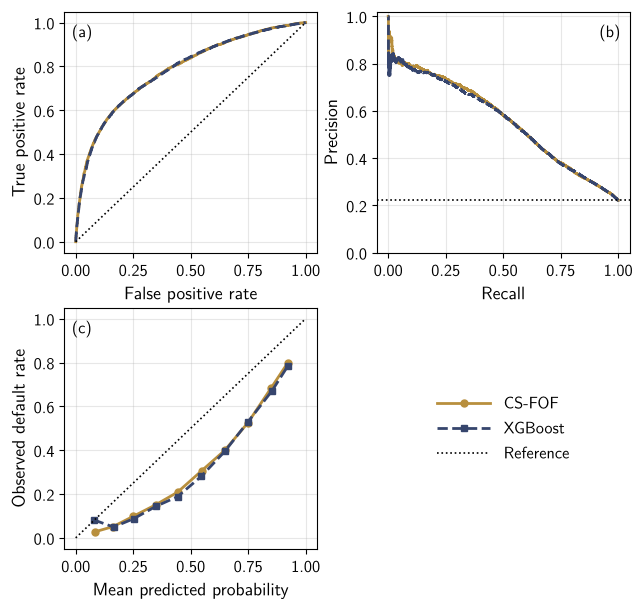

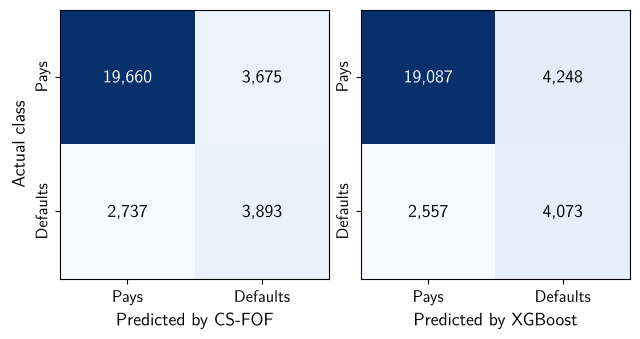

In [16]:
fp.roc_pr_cal_cm()

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">6.4 Estudio de ablación</h3>

Cada variante cambia un solo componente de CS-FOF y mantiene el resto fijo. Se evaluó solo con el entrenamiento del pliegue externo 1, con validación interna de 3 pliegues, sin tocar datos de prueba.

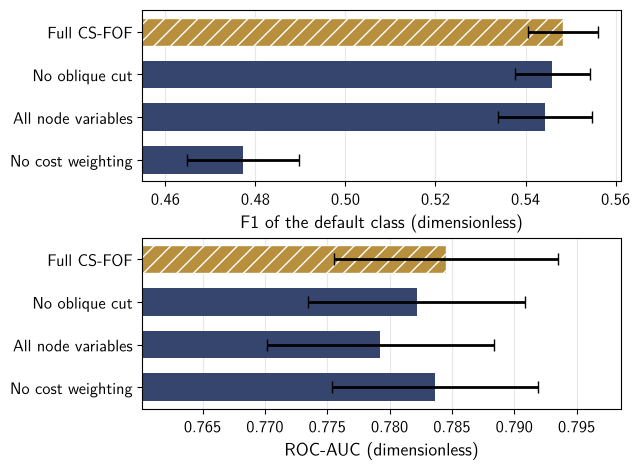

In [17]:
fp.ablacion()

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">6.5 Robustez: ruido en las variables, menos datos y semillas distintas</h3>

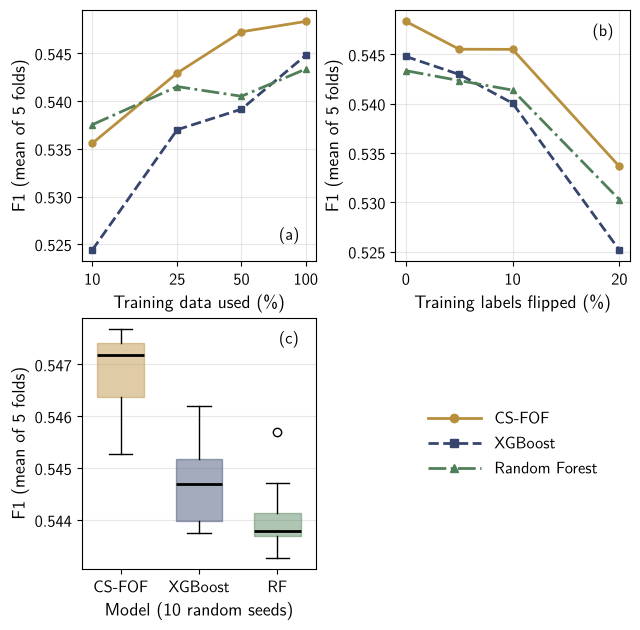

In [18]:
fp.sensibilidad()

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">6.6 Interpretabilidad: SHAP global de CS-FOF frente a XGBoost</h3>

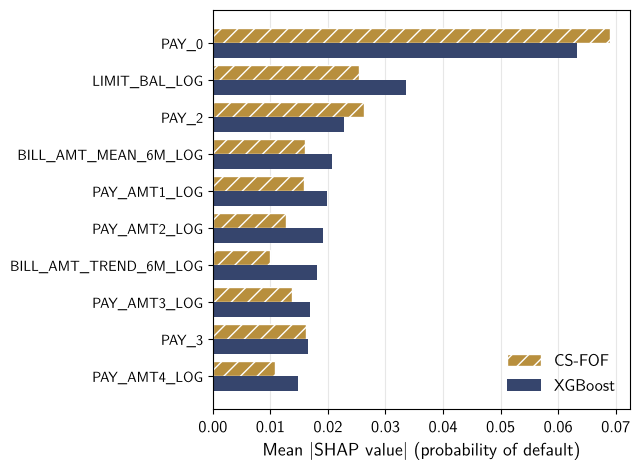

In [19]:
fp.shap()

<h3 style="color:#1A233D;border-left:5px solid #B88F3D;padding-left:10px;margin-top:18px">6.7 Conjuntos de datos adicionales</h3>

Los 8 modelos, con pesos de clase y búsqueda aleatoria, en tres conjuntos públicos de UCI: German Credit, Australian Credit y Polish Companies Bankruptcy (año 1).

In [20]:
cj = json.load(open(PROJECT_ROOT / "experiments" / "paper" / "friedman_exigidos.json"))["conjuntos"]
T = pd.DataFrame(cj["f1"]).T
T["rango medio"] = pd.Series(cj["rangos"])
display(tabla(T.sort_values("rango medio"), resaltar="cs_fof"))
print(f"Friedman entre los 4 conjuntos: chi2 = {cj['chi2']:.2f}, p = {cj['p_chi2']:.3f} · "
      f"Iman-Davenport F = {cj['iman_davenport_F']:.2f}, p = {cj['p_F']:.3f} · CD de Nemenyi = {cj['nemenyi_cd']:.2f}")

,taiwan,german,australian,polish,rango medio
xgboost,0.5466,0.5990,0.8801,0.6825,2.0000
random_forest,0.5452,0.5997,0.8741,0.4462,3.0000
cs_fof,0.5479,0.5889,0.8741,0.4297,3.2500
svm,0.5387,0.6012,0.8619,0.1670,4.0000
knn,0.5264,0.5601,0.8772,0.1382,5.0000
logistic_regression,0.5182,0.5999,0.8718,0.1300,5.2500
decision_tree,0.5254,0.5206,0.8599,0.4287,6.2500
naive_bayes,0.4987,0.5912,0.8368,0.0739,7.2500


Friedman entre los 4 conjuntos: chi2 = 14.50, p = 0.043 · Iman-Davenport F = 3.22, p = 0.018 · CD de Nemenyi = 5.25


<h2 style="color:#1A233D;border-bottom:3px solid #D2BB89;padding-bottom:6px;margin-top:22px"><span style="background:#1A233D;color:#D2BB89;border-radius:8px;padding:2px 12px;margin-right:10px">7</span>Conclusiones</h2>

<div style="background:#F3EFE7;border-left:5px solid #1A233D;border-radius:8px;padding:4px 16px;margin:8px 0;color:#1A233D">

- **CS-FOF obtiene el mayor F1 medio** en el problema principal (0.548) y el mejor rango medio de Friedman (1.4). También es el más estable entre pliegues.
- **No es significativamente superior** a XGBoost ni a Random Forest. La ventaja es de milésimas de F1, menor que la variación entre pliegues, y ni Nemenyi ni Nadeau-Bengio con Holm la separan. Sí supera a SVM, KNN, árbol de decisión, regresión logística y Naive Bayes.
- La **re-ejecución en vivo** del bucle externo reproduce los resultados: Random Forest de forma exacta, y CS-FOF y XGBoost con diferencias de milésimas atribuibles al sistema operativo.
- En los **conjuntos adicionales** XGBoost tiene el mejor rango medio. CS-FOF pierde sobre todo en el conjunto polaco, que tiene muy pocos positivos (3.9 %).
- La ablación muestra que el corte oblicuo aporta, aunque poco. La teoría garantiza que cada corte es al menos tan bueno como el mejor corte recto en entrenamiento, pero no que el bosque gane en datos nuevos; eso solo lo deciden las pruebas.

El paper, el Jupyter Book, el dashboard y el repositorio documentan el resto del proyecto: protocolo pre-registrado, ficha del modelo, declaración de datos y reproducibilidad.

</div>